# Project 2. Concrete Compressive Strength
**DSC8307 Data Mining, Modeling and Analytics. Advent 2026**


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, FunctionTransformer
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import PartialDependenceDisplay
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
sns.set_theme(style="whitegrid")

## 1. Data exploration

In [3]:
df = pd.read_csv("./data/Concrete_Data.csv")
df.columns = ["cement","slag","fly_ash","water","superplast","coarse_agg","fine_agg","age","strength"]
print(df.shape)
print("Missing values:", df.isna().sum().sum(), "| Duplicate rows:", df.duplicated().sum())
df.describe().T.round(1)

(1030, 9)
Missing values: 0 | Duplicate rows: 25


,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.2,104.5,102.0,192.4,272.9,350.0,540.0
slag,1030.0,73.9,86.3,0.0,0.0,22.0,143.0,359.4
fly_ash,1030.0,54.2,64.0,0.0,0.0,0.0,118.3,200.1
water,1030.0,181.6,21.4,121.8,164.9,185.0,192.0,247.0
superplast,1030.0,6.2,6.0,0.0,0.0,6.4,10.2,32.2
coarse_agg,1030.0,972.9,77.8,801.0,932.0,968.0,1029.4,1145.0
fine_agg,1030.0,773.6,80.2,594.0,731.0,779.5,824.0,992.6
age,1030.0,45.7,63.2,1.0,7.0,28.0,56.0,365.0
strength,1030.0,35.8,16.7,2.3,23.7,34.4,46.1,82.6


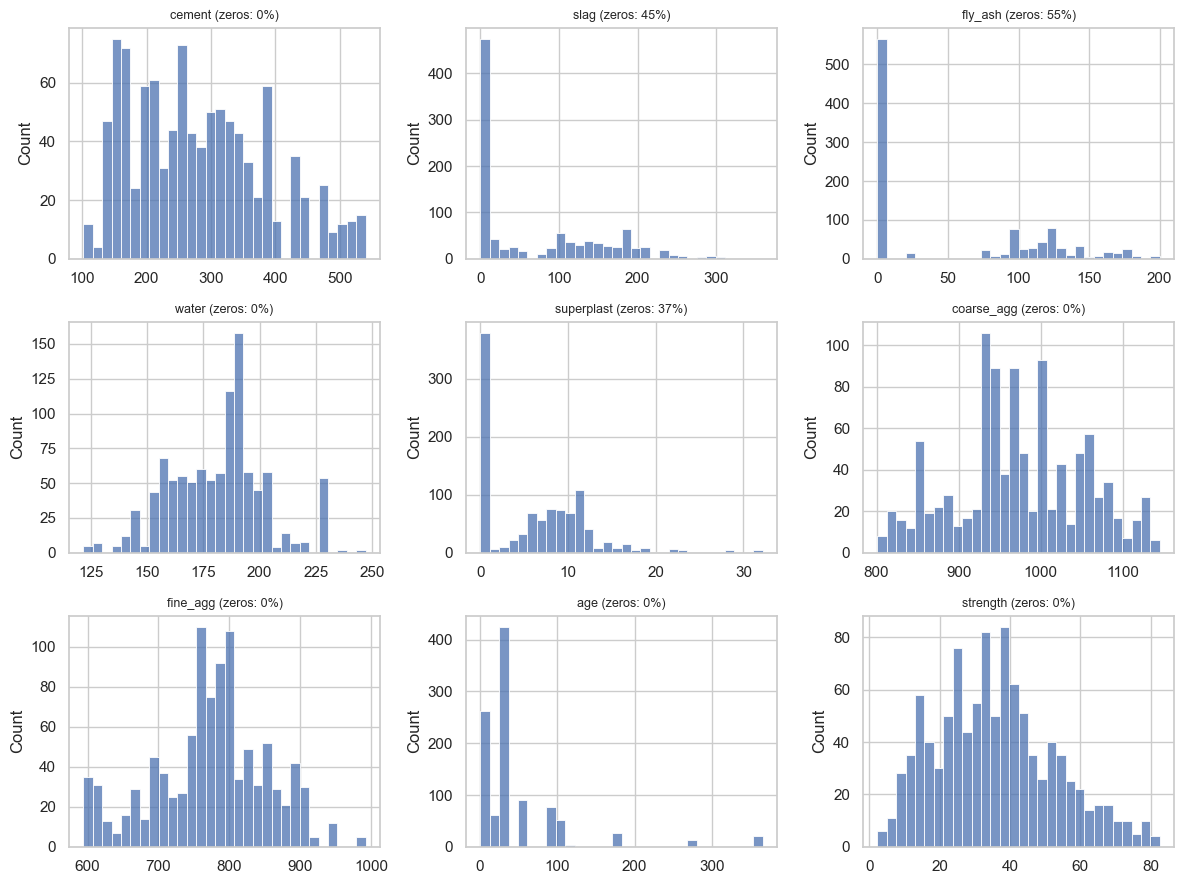

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for ax, c in zip(axes.flat, df.columns):
    sns.histplot(df[c], ax=ax, bins=30)
    ax.set_title(f"{c} (zeros: {(df[c]==0).mean():.0%})", fontsize=9); ax.set_xlabel("")
plt.tight_layout(); plt.show()

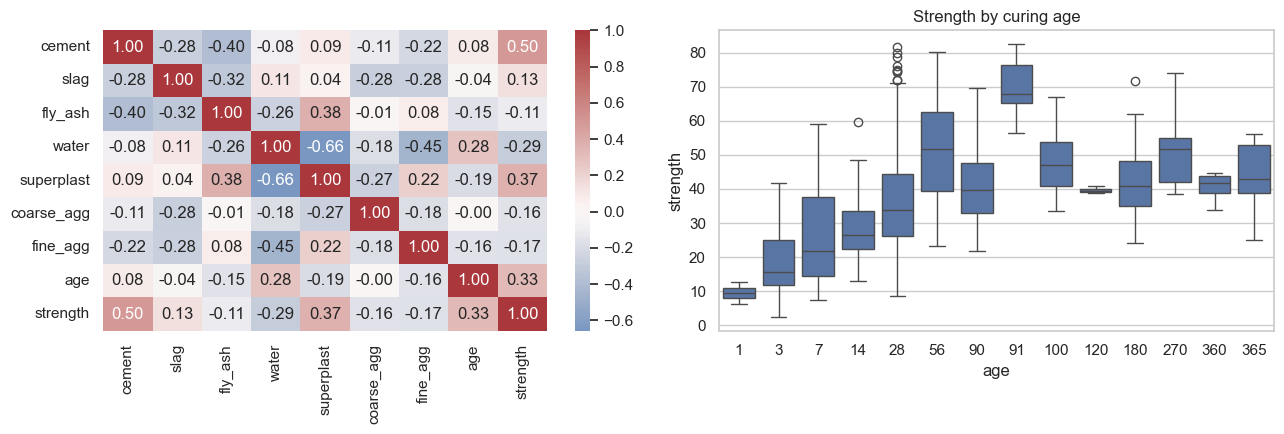

{1: 2, 3: 134, 7: 126, 14: 62, 28: 425, 56: 91, 90: 54, 91: 22, 100: 52, 120: 3, 180: 26, 270: 13, 360: 6, 365: 14}


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax[0])
sns.boxplot(x="age", y="strength", data=df, ax=ax[1]); ax[1].set_title("Strength by curing age")
plt.tight_layout(); plt.show()
print(df["age"].value_counts().sort_index().to_dict())

**Findings**
- No missing values. 25 exact duplicate rows exist.
- Slag, fly ash and superplasticizer are zero in many mixes (zero-inflated). These are real "not used" values, not missing.
- Age is discrete (14 values, mostly 28 days) and right-skewed. Strength rises steeply up to about 28 days then flattens. This is a nonlinear, log-like pattern.
- Cement (r = 0.50), superplasticizer and age correlate positively with strength. Water correlates negatively.
- Limitations. Laboratory data from one source. Few mixes at old ages (over 90 days). No information on cement type, temperature or curing conditions.

## 2. Data preparation
- **Drop duplicates.** They would leak between train and test folds and inflate scores.
- **Keep zeros.** They are valid mix decisions.
- **Engineered features for the linear model only.** `log(age)` captures the curing curve and water/cement ratio follows Abrams' law (strength falls as w/c rises). Tree models get raw inputs.
- **Scaling** inside pipelines so it is fitted on training folds only.
- **Split.** 80/20 hold-out test set, plus 5-fold cross-validation on the training data.

In [6]:
df = df.drop_duplicates().reset_index(drop=True)
X, y = df.drop(columns="strength"), df["strength"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(X_tr.shape, X_te.shape)

def engineer(d):
    d = d.copy()
    d["log_age"] = np.log(d["age"])
    d["w_c"] = d["water"] / d["cement"]
    return d.drop(columns="age")
FE = FunctionTransformer(engineer)

(804, 8) (201, 8)


## 3. Baseline and models

In [7]:
models = {
    "Mean baseline":            DummyRegressor(strategy="mean"),
    "Linear (raw)":             make_pipeline(StandardScaler(), LinearRegression()),
    "Linear (log age + w/c)":   make_pipeline(FE, StandardScaler(), LinearRegression()),
    "Polynomial deg2 (ridge)":  make_pipeline(FE, StandardScaler(), PolynomialFeatures(2), RidgeCV(np.logspace(-3, 3, 20))),
    "Random Forest":            RandomForestRegressor(n_estimators=400, random_state=SEED, n_jobs=-1),
    "Gradient Boosting":        GradientBoostingRegressor(n_estimators=600, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=SEED),
}

cv = KFold(5, shuffle=True, random_state=SEED)
rows = []
for name, m in models.items():
    s = cross_validate(m, X_tr, y_tr, cv=cv, scoring=["neg_root_mean_squared_error", "r2"])
    m.fit(X_tr, y_tr); p = m.predict(X_te)
    rows.append([name, -s["test_neg_root_mean_squared_error"].mean(), s["test_neg_root_mean_squared_error"].std(),
                 s["test_r2"].mean(), np.sqrt(mean_squared_error(y_te, p)), mean_absolute_error(y_te, p), r2_score(y_te, p)])
res = pd.DataFrame(rows, columns=["Model","CV RMSE","CV RMSE sd","CV R2","Test RMSE","Test MAE","Test R2"]).set_index("Model")
res.round(3)

,CV RMSE,CV RMSE sd,CV R2,Test RMSE,Test MAE,Test R2
Model,,,,,,
Mean baseline,16.028,0.590,-0.010,17.297,13.972,-0.003
Linear (raw),10.203,0.153,0.589,11.192,8.896,0.580
Linear (log age + w/c),6.996,0.232,0.806,7.592,5.780,0.807
Polynomial deg2 (ridge),5.703,0.309,0.871,6.182,4.472,0.872
Random Forest,5.363,0.504,0.886,5.095,3.441,0.913
Gradient Boosting,4.576,0.491,0.917,4.263,2.676,0.939


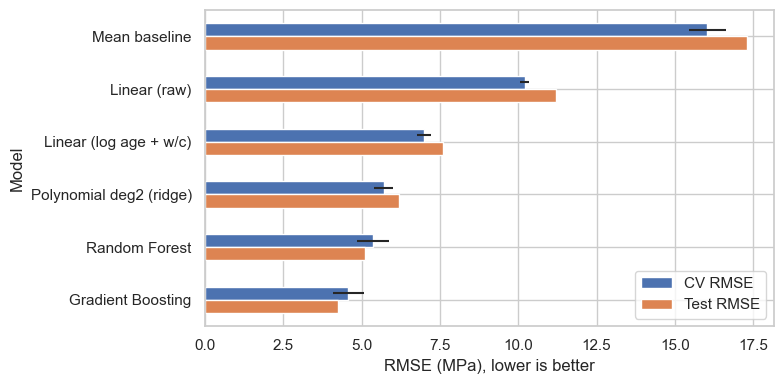

In [8]:
res[["CV RMSE","Test RMSE"]].plot.barh(figsize=(8, 4), xerr={"CV RMSE": res["CV RMSE sd"]})
plt.xlabel("RMSE (MPa), lower is better"); plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

### Sensitivity check. Is the ranking stable across random splits?

In [9]:
sens = {n: [] for n in ["Linear (log age + w/c)", "Random Forest", "Gradient Boosting"]}
for seed in range(10):
    a, b, c, d = train_test_split(X, y, test_size=0.2, random_state=seed)
    for n in sens:
        sens[n].append(np.sqrt(mean_squared_error(d, clone(models[n]).fit(a, c).predict(b))))
pd.DataFrame(sens).describe().loc[["mean","std","min","max"]].round(2)

,Linear (log age + w/c),Random Forest,Gradient Boosting
mean,7.04,4.82,4.02
std,0.30,0.45,0.45
min,6.58,4.23,3.44
max,7.34,5.81,4.95


**Interpretation**
- The mean baseline has test RMSE of 17.3 MPa and R2 of 0. Every model beats it.
- Plain linear regression explains 58% of variance (test RMSE 11.2). Adding `log(age)` and w/c raises R2 to 0.81 (RMSE 7.6). Domain knowledge closes much of the gap.
- Non-linear models do best. Gradient Boosting reaches test RMSE 4.1 MPa and R2 0.94, ahead of Random Forest (5.1) and polynomial ridge (6.2). The ranking holds across 10 random splits (GB mean 4.0, sd 0.5).
- The gap shows strength depends on interactions (e.g. age x cement, slag x age) that an additive model cannot capture.

## 4. Residual diagnostics

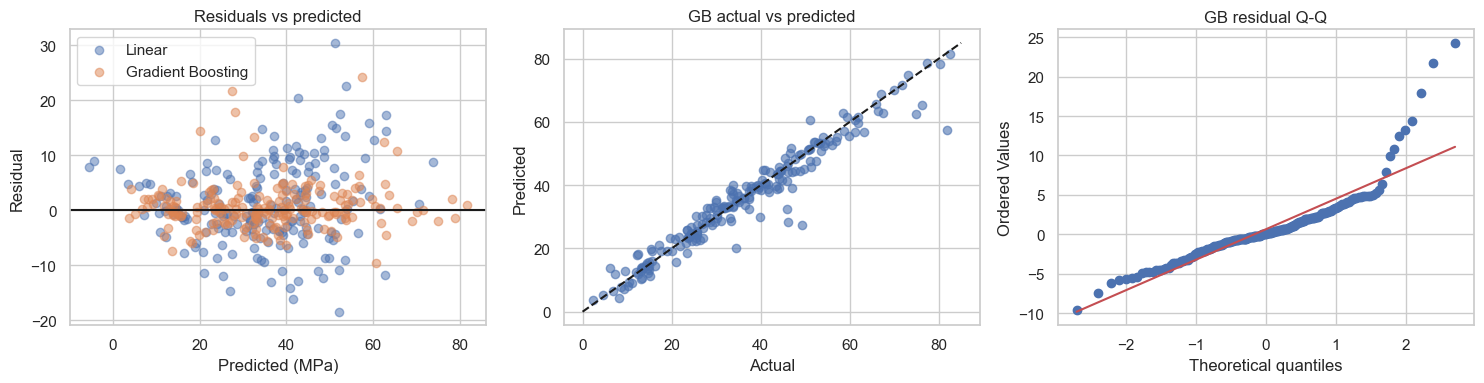

In [10]:
lin, gb = models["Linear (log age + w/c)"], models["Gradient Boosting"]
r = X_te.copy(); r["y"] = y_te
r["res_lin"] = y_te - lin.predict(X_te); r["res_gb"] = y_te - gb.predict(X_te)
r["pred_gb"] = gb.predict(X_te)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(lin.predict(X_te), r.res_lin, alpha=.5, label="Linear")
ax[0].scatter(r.pred_gb, r.res_gb, alpha=.5, label="Gradient Boosting")
ax[0].axhline(0, c="k"); ax[0].set(xlabel="Predicted (MPa)", ylabel="Residual", title="Residuals vs predicted"); ax[0].legend()
ax[1].scatter(y_te, r.pred_gb, alpha=.6); ax[1].plot([0, 85], [0, 85], "k--")
ax[1].set(xlabel="Actual", ylabel="Predicted", title="GB actual vs predicted")
from scipy import stats
stats.probplot(r.res_gb, plot=ax[2]); ax[2].set_title("GB residual Q-Q")
plt.tight_layout(); plt.show()

In [11]:
r["age_grp"] = pd.cut(r.age, [0, 7, 28, 90, 365], labels=["1-7d", "8-28d", "29-90d", "91-365d"])
r["str_grp"] = pd.qcut(r.y, 4, labels=["Low", "Mid-low", "Mid-high", "High"])
r["slag_or_ash"] = np.where((r.slag > 0) | (r.fly_ash > 0), "With slag/fly ash", "Cement only")
mae = lambda s: s.abs().mean()
for g in ["age_grp", "str_grp", "slag_or_ash"]:
    print(r.groupby(g, observed=True).agg(n=("y", "size"), MAE_linear=("res_lin", mae), MAE_GB=("res_gb", mae)).round(2), "\n")

          n  MAE_linear  MAE_GB
age_grp                        
1-7d     56        4.20    2.92
8-28d    89        6.26    3.12
29-90d   27        5.52    1.95
91-365d  29        7.59    1.51 

           n  MAE_linear  MAE_GB
str_grp                         
Low       51        4.13    2.05
Mid-low   50        4.76    2.44
Mid-high  50        4.61    2.58
High      50        9.66    3.64 

                     n  MAE_linear  MAE_GB
slag_or_ash                               
Cement only         52        4.68    2.32
With slag/fly ash  149        6.16    2.80 



**Where predictions are weakest**
- The linear model shows a curved residual pattern and a funnel shape. It under-predicts high-strength mixes and over-predicts weak ones. This breaks the linearity and constant-variance assumptions.
- Gradient Boosting residuals are centred near zero with no clear trend, but tails are heavier than normal (Q-Q plot).
- Both models are weakest on **high-strength mixes** (top quartile MAE. Linear 9.7, GB 3.6 MPa). These are rarer and depend on high cement plus superplasticizer interactions.
- GB errors are largest at **early ages (1 to 28 days)**, where strength changes fastest. The linear model is worst at **late ages (over 90 days)**, where few samples exist and the log-age curve flattens.
- Mixes with slag or fly ash are slightly harder for both models. These materials gain strength slowly, so their effect depends on age.

## 5. QN 3- Does cement content *cause* strength? 

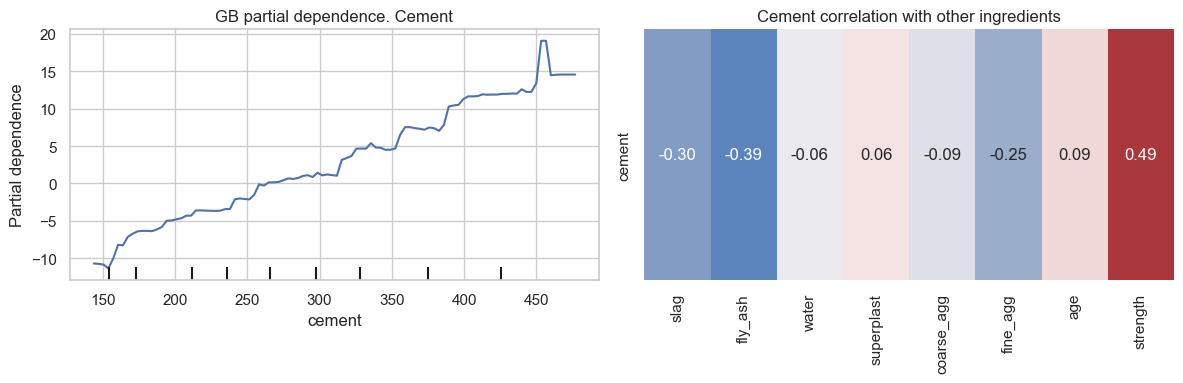

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
PartialDependenceDisplay.from_estimator(gb, X_tr, ["cement"], ax=ax[0])
ax[0].set_title("GB partial dependence. Cement")
sns.heatmap(df.corr()[["cement"]].drop("cement").T, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax[1], cbar=False)
ax[1].set_title("Cement correlation with other ingredients")
plt.tight_layout(); plt.show()

**No. A predictive association does not prove what will happen if we change the mix.**

1. **Observational data, not an experiment.** Mixes were designed by engineers, not randomised. Cement is linked to slag, fly ash and water (see the heatmap). Raising cement in practice usually changes these too, so the model sees their joint effect.
2. **Mixture constraint.** Ingredients share one cubic metre. Adding cement means removing something else. "Change cement, hold all else fixed" may describe a mix that cannot be made.
3. **The model learns correlation, not mechanism.** Partial dependence averages over observed mixes and assumes independence between features. With correlated inputs it can describe unrealistic combinations.
4. **Unmeasured confounders.** Cement type, aggregate quality, temperature and curing method are absent.
5. **Extrapolation.** Predictions are only reliable inside the observed range (102 to 540 kg/m³).

The positive link is plausible from cement chemistry (more binder, more hydration product), but only controlled trials that vary cement while holding w/c ratio and other ingredients fixed can confirm the size of the effect. The model is suitable for **screening** candidate mixes, which must then be verified by laboratory tests.

## 6. Conclusion
- **Best model.** Gradient Boosting (test RMSE 4.1 MPa, R2 0.94) versus a mean baseline of 17.3 MPa.
- **Linear vs non-linear.** Feature engineering helps the linear model a lot, but non-linear models capture age and ingredient interactions better.
- **Weak spots.** High-strength mixes, early ages (GB) and late ages (linear).
- **Use responsibly.** Use for prediction and mix screening only, not causal claims.

